In [1]:
import sys

print(sys.executable)

c:\Users\91703\OneDrive\Desktop\Titanic-Explainable-AI\.venv\Scripts\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
#Load Titanic Dataset

# Load training dataset
train_df = pd.read_csv("../dataset/train.csv")

# Load testing dataset
test_df = pd.read_csv("../dataset/test.csv")

print("Datasets loaded successfully!")

Datasets loaded successfully!


In [4]:
print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape:", test_df.shape)

Training Dataset Shape: (891, 12)
Testing Dataset Shape: (418, 11)


In [5]:
#Understand Dataset Structure
# Display first 5 rows
train_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [6]:
# Display all column names
train_df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [7]:
'''Important ML concepts
1. Target Variable

Survived is our target variable (y).

2. Input Features

Remaining useful passenger information will be considered as input features (X).

3. Unique Identifier

PassengerId is an identifier, not normally a useful predictive feature.'''

'Important ML concepts\n1. Target Variable\n\nSurvived is our target variable (y).\n\n2. Input Features\n\nRemaining useful passenger information will be considered as input features (X).\n\n3. Unique Identifier\n\nPassengerId is an identifier, not normally a useful predictive feature.'

In [8]:
train_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [9]:
# dataset information
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [10]:
#Count Missing values
train_df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [11]:
train_df.isnull().sum().sum()

np.int64(866)

In [12]:
#Missing values percentage 
missing_percentage = (train_df.isnull().sum() / len(train_df)) * 100

missing_percentage

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64

In [13]:
'''
Step 24: Analysis
Column	       Missing %	   Observation
Age	            19.87%	      Moderate missing data
Cabin	        77.10%	      Very high missing data
Embarked	    0.22%	      Very low missing data

Important ML observations:
- Age: We can consider median imputation.
- Cabin: Missing data is very high; we may extract cabin deck information or consider dropping the original column.
- Embarked: We can consider mode imputation.'''

'\nStep 24: Analysis\nColumn\t       Missing %\t   Observation\nAge\t            19.87%\t      Moderate missing data\nCabin\t        77.10%\t      Very high missing data\nEmbarked\t    0.22%\t      Very low missing data\n\nImportant ML observations:\n- Age: We can consider median imputation.\n- Cabin: Missing data is very high; we may extract cabin deck information or consider dropping the original column.\n- Embarked: We can consider mode imputation.'

In [14]:
train_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [15]:
'''What will this show?
- Mean
- Standard deviation
- Minimum value
- 25%, 50%, 75% percentiles
- Maximum value'''

'What will this show?\n- Mean\n- Standard deviation\n- Minimum value\n- 25%, 50%, 75% percentiles\n- Maximum value'

In [16]:
#Check Target Variable Distribution with percentage
train_df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [17]:
train_df["Survived"].value_counts(normalize=True) * 100

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

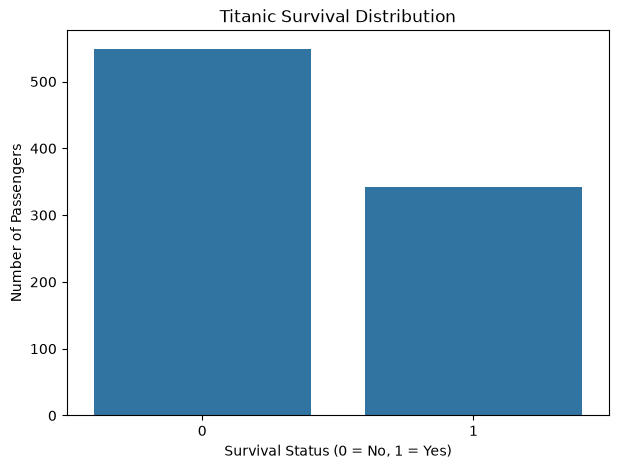

In [18]:
#First Visualization – Survival Count
plt.figure(figsize=(7, 5))

sns.countplot(data=train_df, x="Survived")

plt.title("Titanic Survival Distribution")
plt.xlabel("Survival Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train_df = pd.read_csv("../dataset/train.csv")
test_df = pd.read_csv("../dataset/test.csv")

In [ ]:
#Count Survival with percentage
train_df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [3]:
survival_percentage = train_df["Survived"].value_counts(normalize=True) * 100

survival_percentage

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

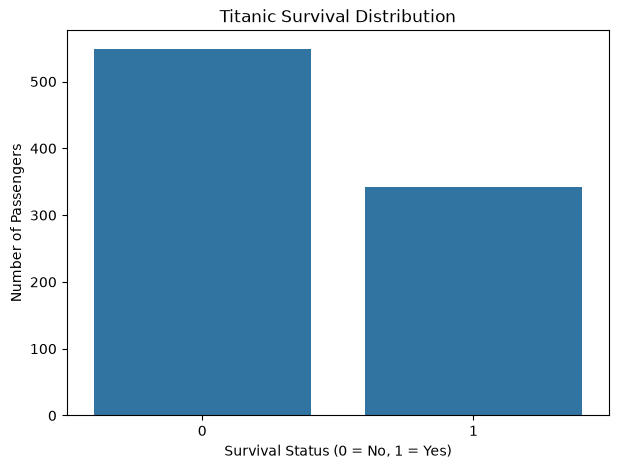

In [4]:
#Visualize Survival Distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=train_df, x="Survived")

plt.title("Titanic Survival Distribution")
plt.xlabel("Survival Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

In [ ]:
#Graph Interpretation
'''Observations:
1. The dataset contains 891 passengers.
2. Out of 891 passengers, 342 survived and 549 did not survive.
3. Approximately 38.38% passengers survived.
4. Approximately 61.62% passengers did not survive.
5. The dataset contains more non-survivors than survivors.'''

In [ ]:
#Gender Analysis
'''Did more female passengers survive than male passengers?

We'll calculate:
1. Male and female passenger counts.
2. Survival count by gender.
3. Survival percentage by gender.
4. Comparative visualization.'''

In [ ]:
'''Gender Analysis means studying the relationship between passenger gender and survival.

Our dataset has a column named Sex, containing two categories:
- male
- female
We want to investigate whether survival rates were different for male and female passengers.'''

In [5]:
#Step 1: Count Male and Female Passengers

train_df["Sex"].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [6]:
#Gender-wise Survival Count
pd.crosstab(train_df["Sex"], train_df["Survived"])

Survived,0,1
Sex,,
female,81,233
male,468,109


In [ ]:
# Did not survive (0)	Survived (1)

In [7]:
#Gender-wise Survival Percentage
gender_survival = pd.crosstab(
    train_df["Sex"],
    train_df["Survived"],
    normalize="index"
) * 100

gender_survival

Survived,0,1
Sex,,
female,25.796178,74.203822
male,81.109185,18.890815


In [ ]:
'''Gender Analysis Observations:

1. The dataset contains 577 male and 314 female passengers.
2. Approximately 74.20% of female passengers survived.
3. Approximately 18.89% of male passengers survived.
4. Female passengers had a significantly higher survival rate than male passengers.
5. Gender appears to be an important feature associated with survival in this dataset.'''

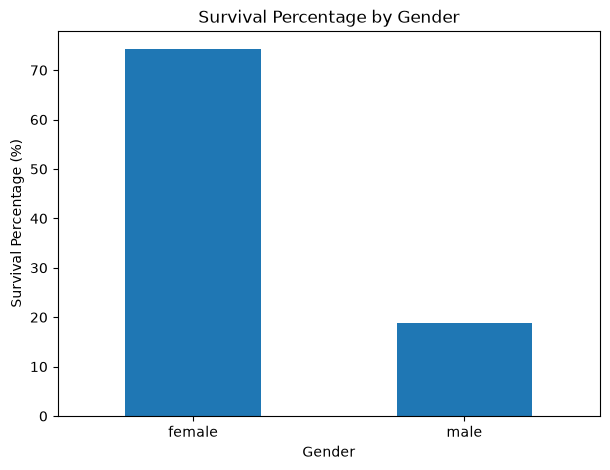

In [8]:
#Gender Survival Visualization
gender_survival[1].plot(kind="bar", figsize=(7, 5))

plt.title("Survival Percentage by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Percentage (%)")
plt.xticks(rotation=0)
plt.show()



In [ ]:
#Passenger Class Analysis
'''Passenger Class Analysis means studying how passenger ticket class is associated with survival.

The Titanic dataset has a column named Pclass.
Pclass value	Meaning
1	           First Class
2	           Second Class
3	           Third Class

Our objective is to compare survival rates across all three passenger classes.'''

In [9]:
#Count Passengers by Class
train_df["Pclass"].value_counts().sort_index()

Pclass
1    216
2    184
3    491
Name: count, dtype: int64

In [10]:
#Understand Passenger Count
pd.crosstab(train_df["Pclass"], train_df["Survived"])

Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


In [11]:
#percentage
class_survival = pd.crosstab(
    train_df["Pclass"],
    train_df["Survived"],
    normalize="index"
) * 100

class_survival

Survived,0,1
Pclass,,
1,37.037037,62.962963
2,52.717391,47.282609
3,75.763747,24.236253


In [ ]:
'''
Pclass	Did not survive (0)	Survived (1)
1	         37.04%	         62.96%
2	         52.72%	         47.28%
3	         75.76%	         24.24%
'''

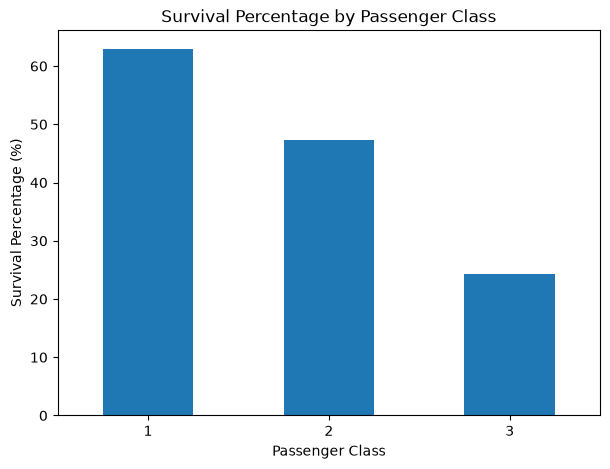

In [12]:
#Visualize Class-wise Survival
class_survival[1].plot(kind="bar", figsize=(7, 5))

plt.title("Survival Percentage by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Percentage (%)")
plt.xticks(rotation=0)
plt.show()

In [ ]:
#result
'''
First Class: approximately 62.96% survived.

Second Class: approximately 47.28% survived.

Third Class: approximately 24.24% survived.
'''

In [ ]:
#Observation 
'''
Passenger Class Analysis Observations:

1. The dataset contains 216 First Class, 184 Second Class,
   and 491 Third Class passengers.

2. First Class passengers had the highest survival rate
   of approximately 62.96%.

3. Second Class passengers had a survival rate
   of approximately 47.28%.

4. Third Class passengers had the lowest survival rate
   of approximately 24.24%.

5. Passenger class appears to be an important feature
   associated with survival.
   '''

In [ ]:
#Age Analysis
'''
Age distribution.
Missing age values.
Age distribution of survivors vs non-survivors.
Survival percentage across age groups.
'''

'''
Age Analysis means studying how passenger age is associated with survival.

Our dataset contains a column named Age, which represents the age of each passenger.

We want to investigate:
- What is the average passenger age?
- What is the youngest and oldest passenger age?
- How many age values are missing?
- Did children and adults have different survival patterns?
'''

In [13]:
#Understand Age Statistics
train_df["Age"].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

In [14]:
#Check Missing Age Values
train_df["Age"].isnull().sum()

np.int64(177)

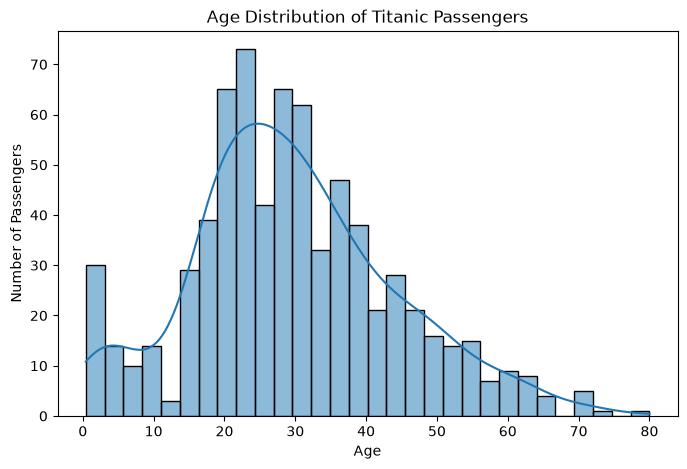

In [15]:
#Visualization
plt.figure(figsize=(8, 5))

sns.histplot(data=train_df, x="Age", bins=30, kde=True)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

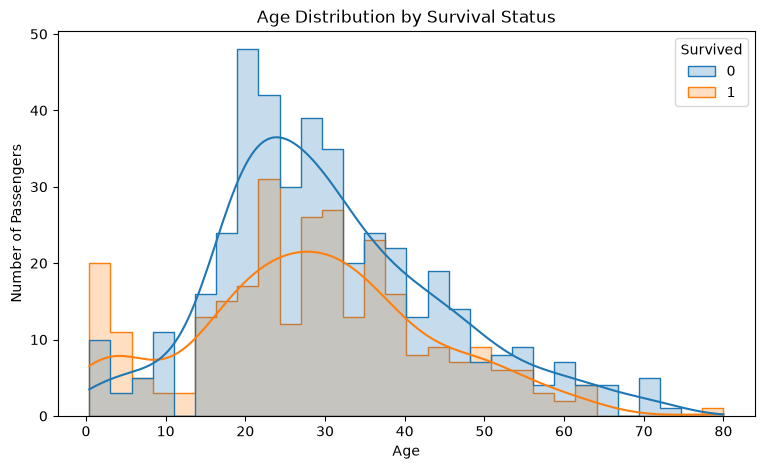

In [16]:
#Age vs Survival Analysis
plt.figure(figsize=(9, 5))

sns.histplot(
    data=train_df,
    x="Age",
    hue="Survived",
    bins=30,
    kde=True,
    element="step"
)

plt.title("Age Distribution by Survival Status")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

In [17]:
#Survival by Age Group
train_df["AgeGroup"] = pd.cut(
    train_df["Age"],
    bins=[0, 18, 60, 100],
    labels=["Child", "Adult", "Senior"],
    right=False
)

train_df["AgeGroup"].value_counts()

AgeGroup
Adult     575
Child     113
Senior     26
Name: count, dtype: int64

In [18]:
#Survival Percentage by Age Group
age_survival = pd.crosstab(
    train_df["AgeGroup"],
    train_df["Survived"],
    normalize="index"
) * 100

age_survival

Survived,0,1
AgeGroup,,
Child,46.017699,53.982301
Adult,61.391304,38.608696
Senior,73.076923,26.923077


In [ ]:
#Key observation: Children had the highest survival percentage (53.98%), while seniors had the lowest (26.92%).

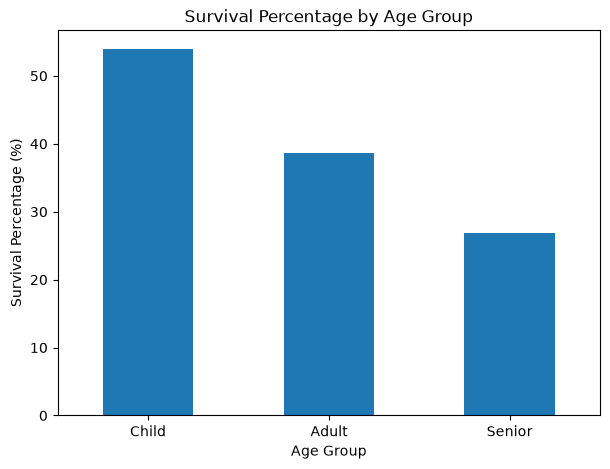

In [19]:
age_survival[1].plot(kind="bar", figsize=(7, 5))

plt.title("Survival Percentage by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Percentage (%)")
plt.xticks(rotation=0)
plt.show()

In [ ]:
'''
Observations 
1. Total 714 passengers had recorded age values.
2. Average passenger age was approximately 29.7 years.
3. 177 passengers had missing age values.
4. Children had the highest survival rate (53.98%).
5. Adults had a survival rate of 38.61%.
6. Seniors had the lowest survival rate (26.92%).
Conclusion: Age appears to be associated with survival in the Titanic dataset. Children had a higher 
survival percentage than adults and seniors.
'''

In [20]:
#Fare Analysis
train_df["Fare"].describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

In [ ]:
'''
Understanding Fare Statistics
Statistic	             Value   	Meaning
Count	                 891	    Total passengers
Mean	                 32.20	    Average ticket fare
Median	                 14.45	    Middle fare value
Minimum	                 0.00   	Lowest recorded fare
Maximum	                 512.33   	Highest recorded fare
Standard Deviation	     49.69	    Fare values mein variation


'''

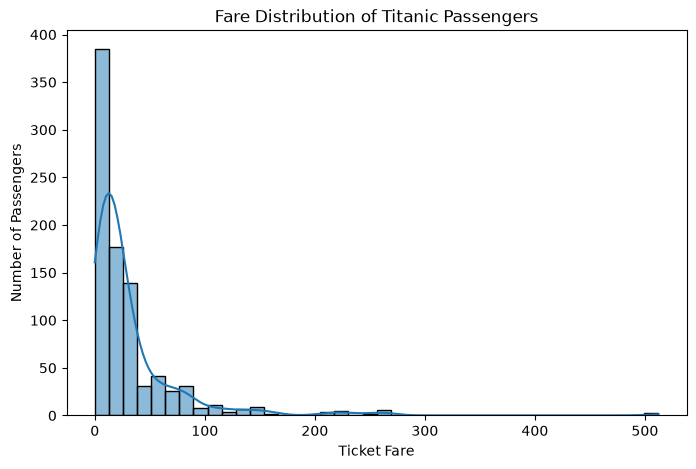

In [21]:
#Fare Distribution 
plt.figure(figsize=(8, 5))

sns.histplot(data=train_df, x="Fare", bins=40, kde=True)

plt.title("Fare Distribution of Titanic Passengers")
plt.xlabel("Ticket Fare")
plt.ylabel("Number of Passengers")

plt.show()

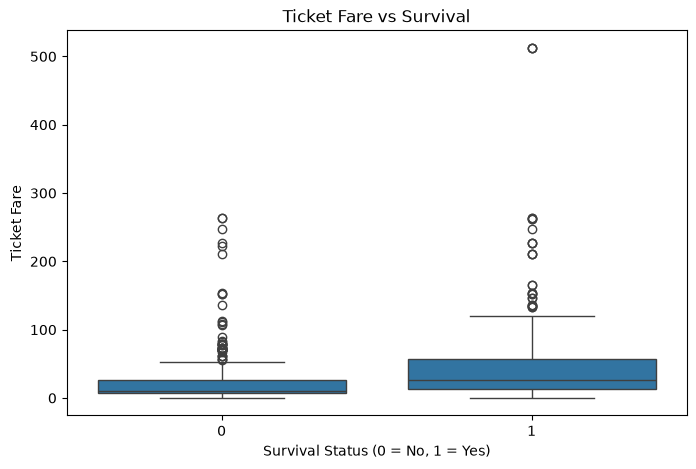

In [22]:
#Fare vs Survival Analysis
plt.figure(figsize=(8, 5))

sns.boxplot(data=train_df, x="Survived", y="Fare")

plt.title("Ticket Fare vs Survival")
plt.xlabel("Survival Status (0 = No, 1 = Yes)")
plt.ylabel("Ticket Fare")

plt.show()

In [ ]:
'''Understanding:
- X-axis: Survival status.
- Y-axis: Ticket fare.
- Boxplot median, spread and outliers'''

In [23]:
#Average Fare by Survival Status
train_df.groupby("Survived")["Fare"].mean()

Survived
0    22.117887
1    48.395408
Name: Fare, dtype: float64

In [ ]:
'''Fare Analysis Observations
Survival Status	    Average Fare
Did Not Survive (0)	22.12
Survived (1)	    48.40

English Notes:
1. Average ticket fare of survivors was approximately 48.40.
2. Average ticket fare of non-survivors was approximately 22.12.
3. Survivors paid more than twice the average fare of non-survivors.
4. Fare appears to be associated with survival.
Conclusion: Passengers who paid higher ticket fares had a higher survival rate in this dataset.
This may also be related to passenger class.'''

In [24]:
#Correlation Analysis
numeric_df = train_df.select_dtypes(include=["number"])

numeric_df.corr()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
PassengerId,1.000000,-0.005007,-0.035144,0.036847,-0.057527,-0.001652,0.012658
Survived,-0.005007,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307
Pclass,-0.035144,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500
Age,0.036847,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067
SibSp,-0.057527,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651
Parch,-0.001652,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225
Fare,0.012658,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000


In [ ]:
'''Understanding Correlation
Correlation measures the strength and direction of the relationship between two numerical variables.

Correlation values range from -1 to +1:
Value	          Meaning
+1	              Perfect positive correlation
Close to +1	      Strong positive relationship
Around 0	      Weak or no linear relationship
Close to -1	      Strong negative relationship
-1	              Perfect negative correlation

Important findings from your output
Features	         Correlation	    Interpretation
Survived  Pclass	-0.338	         Higher class number is associated with lower survival
Survived  Fare	    +0.257	         Higher fare is associated with higher survival
Survived  Age	    -0.077	         Very weak negative relationship
Survived  SibSp	    -0.035	         Almost no linear relationship
Survived  Parch	    +0.082	         Very weak positive relationship

Important: Correlation does not prove causation. Also, Pclass is encoded as 1, 2, and 3,
so its negative correlation with survival reflects lower survival in higher-numbered classes.'''

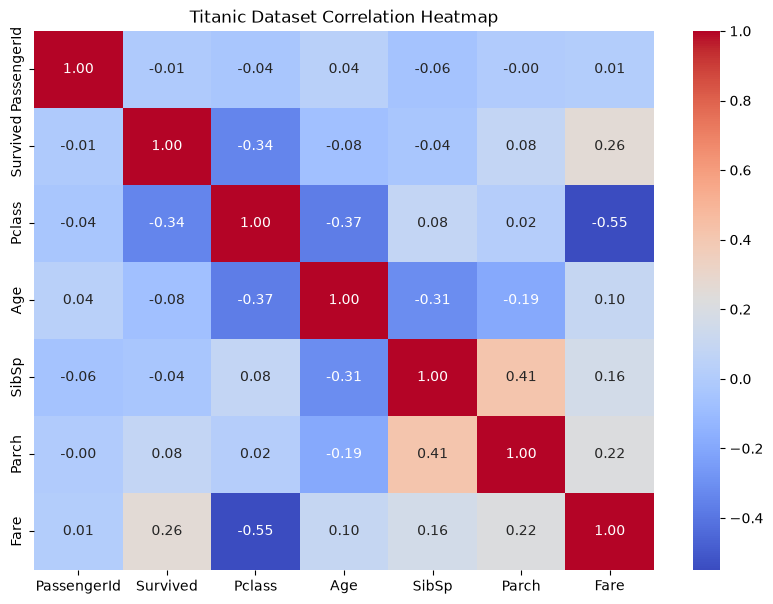

In [25]:
#Create Correlation Heatmap
#Now let's visualize the relationships.
plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Titanic Dataset Correlation Heatmap")
plt.show()

In [ ]:
'''Correlation Analysis Observations
Apne personal notes mein ye observations add karo:
1. Pclass has a negative correlation (-0.338) with survival.
2. Fare has a positive correlation (+0.257) with survival.
3. Age has a very weak negative correlation (-0.077) with survival.
4. SibSp (-0.035) and Parch (+0.082) have very weak linear relationships with survival.
5. Fare and Pclass have a negative correlation (-0.550).
Conclusion: Passenger class and ticket fare show more noticeable relationships
with survival than the other numerical features in this correlation matrix.'''